WEEK 3 – DATA CLEANING AND DATA QUALITY REPORT

In [2]:
from google.colab import files

uploaded = files.upload()

Saving mental_health_in_tech_2016.csv to mental_health_in_tech_2016.csv


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv('mental_health_in_tech_2016.csv')

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1433, 63)


,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,...,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,...,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,...,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,43,male,United Kingdom,NaN,United Kingdom,NaN,Supervisor/Team Lead,Sometimes
4,0,6-25,0.0,1.0,Yes,Yes,No,No,No,Neither easy nor difficult,...,Sometimes,Sometimes,43,Female,United States of America,Illinois,United States of America,Illinois,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes


In [6]:
clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Copy:", clean.shape)

Original Dataset: (1433, 63)
Working Copy: (1433, 63)


In [7]:
missing = clean.isnull().sum()

missing_report = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': (missing / len(clean)) * 100
})

missing_report = missing_report.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_report)

,Missing Values,Missing Percentage
"If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?",1289,89.951151
"If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",1229,85.764131
Is your primary role within your company related to tech/IT?,1170,81.646895
Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,1146,79.972087
"If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?",1146,79.972087
...,...,...
What is your age?,0,0.000000
What country do you live in?,0,0.000000
What country do you work in?,0,0.000000
Which of the following best describes your work position?,0,0.000000


/tmp/ipykernel_1540/2595343012.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


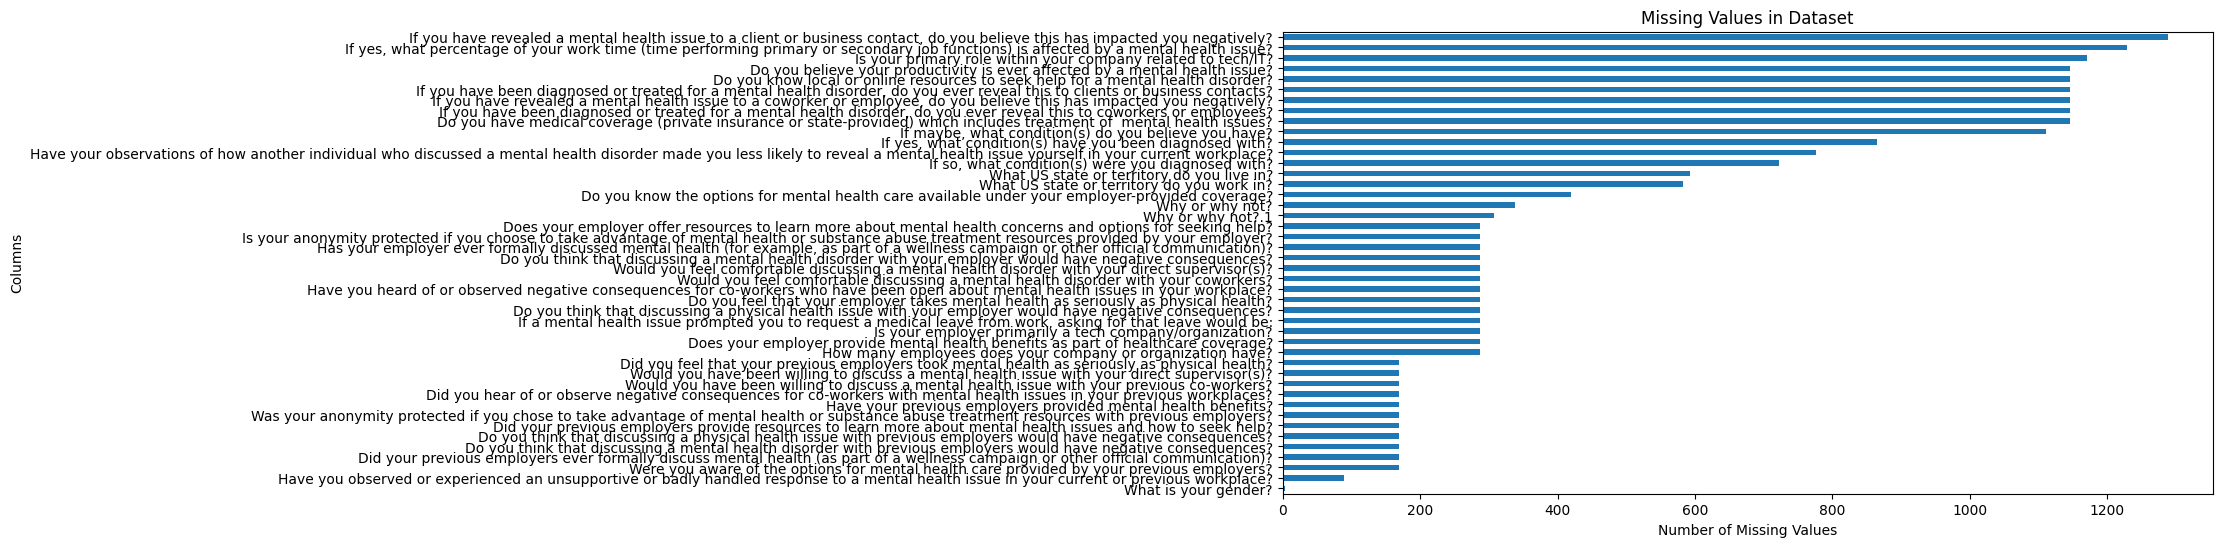

In [8]:
missing_counts = clean.isnull().sum()

missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(12, 6))
missing_counts.sort_values().plot(kind='barh')

plt.title("Missing Values in Dataset")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

In [9]:
print("Duplicate rows:", clean.duplicated().sum())

Duplicate rows: 0


In [10]:
clean = clean.drop_duplicates()

print("After removing duplicates:", clean.shape)

After removing duplicates: (1433, 63)


In [11]:
text_columns = clean.select_dtypes(include='object').columns

for col in text_columns:
    clean[col] = clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Text cleaning completed!")

Text cleaning completed!


In [12]:
age_columns = [col for col in clean.columns
               if 'age' in col.lower()]

print("Age columns:", age_columns)

Age columns: ['Does your employer provide mental health benefits as part of healthcare coverage?', 'Do you know the options for mental health care available under your employer-provided coverage?', 'Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?', 'Do you have medical coverage (private insurance or state-provided) which includes treatment of \xa0mental health issues?', 'If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?', 'Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?', 'What is your age?']


In [13]:
age_col = age_columns[0]

clean[age_col] = pd.to_numeric(
    clean[age_col], errors='coerce'
)

invalid_age = (
    (clean[age_col] < 18) |
    (clean[age_col] > 100)
)

print("Invalid age values:", invalid_age.sum())

clean.loc[invalid_age, age_col] = np.nan

# Fill missing age using median
clean[age_col] = clean[age_col].fillna(
    clean[age_col].median()
)

print("Age validation completed!")

Invalid age values: 0
Age validation completed!


In [14]:
Q1 = clean[age_col].quantile(0.25)
Q3 = clean[age_col].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = clean[
    (clean[age_col] < lower) |
    (clean[age_col] > upper)
]

print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Number of IQR Outliers:", len(outliers))

Lower Bound: nan
Upper Bound: nan
Number of IQR Outliers: 0


In [16]:
print("Missing Values Before Cleaning:",
      df.isnull().sum().sum())

print("Missing Values After Cleaning:",
      clean.isnull().sum().sum())

print("Final Dataset Shape:", clean.shape)

Missing Values Before Cleaning: 21960
Missing Values After Cleaning: 23106
Final Dataset Shape: (1433, 63)


In [17]:
quality_report = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Original Columns",
        "Final Rows",
        "Final Columns",
        "Duplicates Before Cleaning",
        "Missing Values Before Cleaning",
        "Missing Values After Cleaning",
        "Invalid Age Values",
        "IQR Age Outliers"
    ],

    "Value": [
        df.shape[0],
        df.shape[1],
        clean.shape[0],
        clean.shape[1],
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        clean.isnull().sum().sum(),
        invalid_age.sum(),
        len(outliers)
    ]
})

display(quality_report)

quality_report.to_csv(
    "Data_Quality_Report.csv",
    index=False
)

print("Data Quality Report Generated!")

,Metric,Value
0,Original Rows,1433
1,Original Columns,63
2,Final Rows,1433
3,Final Columns,63
4,Duplicates Before Cleaning,0
5,Missing Values Before Cleaning,21960
6,Missing Values After Cleaning,23106
7,Invalid Age Values,0
8,IQR Age Outliers,0


Data Quality Report Generated!
